# Lista 7 — Perceptron e Backpropagation

**Aluno:** Paulo Gabriel de Oliveira Leite

Implementação apenas com NumPy, Pandas e Matplotlib. Semente fixa (`np.random.seed(42)`) em todos os experimentos.

In [1]:
# Bibliotecas permitidas: NumPy, Pandas e Matplotlib.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42  # semente usada em todos os experimentos

# Paleta dos gráficos: azul = classe 0, laranja = classe 1
AZUL, LARANJA, VERDE, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
FUNDO0, FUNDO1 = "#dbe9fb", "#fde3d7"   # regiões de decisão 0 e 1
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA,
                     "xtick.color": TINTA, "ytick.color": TINTA, "font.size": 10,
                     "axes.titlesize": 11, "axes.grid": True,
                     "grid.color": "#e4e3dd", "grid.linewidth": 0.6})
pd.set_option("display.precision", 4)

---
# Parte 1 — Perceptron

**Decisões:** bias como peso $w_0$ de uma entrada fixa $x_0 = 1$; atualização a cada instância, na ordem da tabela-verdade; erros por época = nº de atualizações na época; parada na primeira época sem erros ou em 100 épocas.

In [2]:
X_LOGICO = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
ALVOS = {"AND": np.array([0, 0, 0, 1]),
         "OR":  np.array([0, 1, 1, 1]),
         "XOR": np.array([0, 1, 1, 0])}

pd.DataFrame(np.column_stack([X_LOGICO.astype(int)] + list(ALVOS.values())),
             columns=["x1", "x2", "AND", "OR", "XOR"])

,x1,x2,AND,OR,XOR
0,0,0,0,0,0
1,0,1,0,1,1
2,1,0,0,1,1
3,1,1,1,1,0


## Exercício 1 — Classe `Perceptron`

In [3]:
class Perceptron:
    # Perceptron de Rosenblatt: ativação degrau e bias como peso w0 (entrada x0 = 1).

    def __init__(self, eta=0.1, max_epocas=100, w_inicial=None, seed=SEED):
        self.eta = eta
        self.max_epocas = max_epocas
        self.w_inicial = None if w_inicial is None else np.asarray(w_inicial, dtype=float)
        self.seed = seed

    @staticmethod
    def _com_bias(X):
        return np.c_[np.ones(len(X)), X]                 # acrescenta a coluna x0 = 1

    def inicializar_pesos(self, n_atributos):
        if self.w_inicial is not None:                   # permite repetir os mesmos pesos
            return self.w_inicial.copy()
        np.random.seed(self.seed)
        return np.random.uniform(-1, 1, n_atributos + 1) # [w0, w1, ..., wn] em [-1, +1]

    def net_input(self, X):
        return self._com_bias(np.asarray(X, float)) @ self.w   # z = w0 + w1 x1 + ...

    def predict(self, X):
        return (self.net_input(X) >= 0).astype(int)      # degrau: 1 se z >= 0

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, int)
        Xb = self._com_bias(X)
        self.w = self.inicializar_pesos(X.shape[1])
        self.pesos_iniciais_ = self.w.copy()
        self.erros_por_epoca_, self.pesos_por_epoca_, self.acuracia_por_epoca_ = [], [], []
        self.n_atualizacoes_, self.convergiu_ = 0, False

        for epoca in range(1, self.max_epocas + 1):
            erros = 0
            for xi, yi in zip(Xb, y):
                y_hat = int(xi @ self.w >= 0)
                if y_hat != yi:                                      # errou -> atualiza
                    self.w = self.w + self.eta * (yi - y_hat) * xi   # w_i <- w_i + η(y - ŷ)x_i
                    erros += 1
            self.n_atualizacoes_ += erros
            self.erros_por_epoca_.append(erros)
            self.pesos_por_epoca_.append(self.w.copy())
            self.acuracia_por_epoca_.append(np.mean(self.predict(X) == y))
            if erros == 0:                                           # época sem erros
                self.convergiu_ = True
                break
        self.epocas_ = epoca
        return self

    def historico(self):
        # Tabela com, para cada época: nº de erros, pesos ao fim da época e acurácia.
        nomes = [f"w{i}" for i in range(len(self.w))]
        tab = pd.DataFrame(self.pesos_por_epoca_, columns=nomes)
        tab.insert(0, "erros", self.erros_por_epoca_)
        tab.insert(0, "época", range(1, len(tab) + 1))
        tab["acurácia"] = self.acuracia_por_epoca_
        return tab

In [4]:
# Funções auxiliares de gráfico (pontos, reta e regiões de decisão)
def equacao(w):
    return f"{w[0]:+.3f} {w[1]:+.3f}·x1 {w[2]:+.3f}·x2 = 0"

def plotar_pontos(ax, y):
    for classe, cor, marca in [(0, AZUL, "o"), (1, LARANJA, "s")]:
        m = y == classe
        ax.scatter(X_LOGICO[m, 0], X_LOGICO[m, 1], s=110, c=cor, marker=marca,
                   edgecolor="white", linewidth=2, zorder=4, label=f"classe {classe}")
    ax.set(xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), xlabel="x1", ylabel="x2")
    ax.set_aspect("equal")

def plotar_reta(ax, w, rotulo=None, estilo="-", cor=TINTA):
    x1 = np.linspace(-0.5, 1.5, 200)
    if abs(w[2]) > 1e-12:
        ax.plot(x1, -(w[0] + w[1] * x1) / w[2], estilo, color=cor, lw=2, label=rotulo)
    elif abs(w[1]) > 1e-12:                                   # reta vertical
        ax.axvline(-w[0] / w[1], ls=estilo, color=cor, lw=2, label=rotulo)

def plotar_regioes(ax, modelo):
    g = np.linspace(-0.5, 1.5, 300)
    xx, yy = np.meshgrid(g, g)
    zz = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=[FUNDO0, FUNDO1])

### 1(a) Pesos iniciais e classificação do AND antes do treino

Os mesmos pesos iniciais são usados em AND, OR e XOR.

In [5]:
W_INICIAL = Perceptron(seed=SEED).inicializar_pesos(2)
print("Pesos iniciais [w0, w1, w2] =", np.round(W_INICIAL, 4))

z_ini = np.c_[np.ones(4), X_LOGICO] @ W_INICIAL
antes = pd.DataFrame({"x1": X_LOGICO[:, 0].astype(int), "x2": X_LOGICO[:, 1].astype(int),
                      "z": z_ini, "ŷ": (z_ini >= 0).astype(int), "y (AND)": ALVOS["AND"]})
antes["acertou?"] = np.where(antes["ŷ"] == antes["y (AND)"], "sim", "não")
print(f"Acurácia antes do treino: {np.mean(antes['ŷ'] == antes['y (AND)']):.0%}")
antes

Pesos iniciais [w0, w1, w2] = [-0.2509  0.9014  0.464 ]
Acurácia antes do treino: 50%


,x1,x2,z,ŷ,y (AND),acertou?
0,0,0,-0.2509,0,0,sim
1,0,1,0.2131,1,0,não
2,1,0,0.6505,1,0,não
3,1,1,1.1145,1,1,sim


### 1(b) Reta inicial junto com os pontos do AND

Reta inicial: -0.251 +0.901·x1 +0.464·x2 = 0


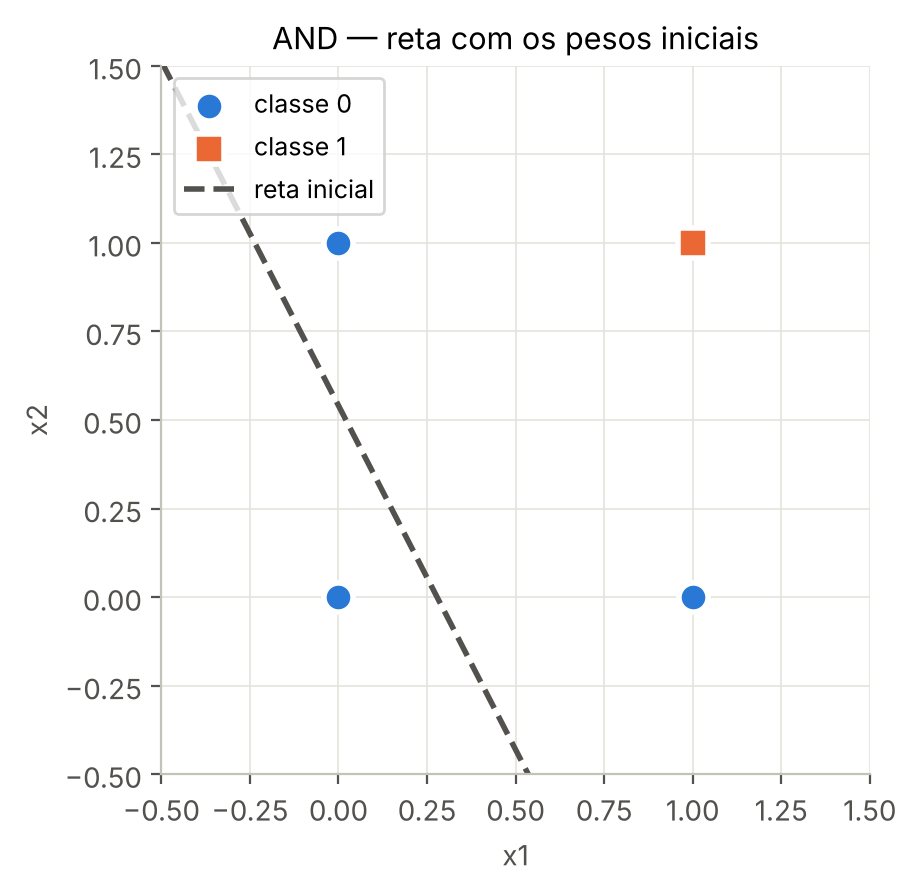

In [6]:
print("Reta inicial:", equacao(W_INICIAL))

fig, ax = plt.subplots(figsize=(4.6, 4.6))
plotar_pontos(ax, ALVOS["AND"])
plotar_reta(ax, W_INICIAL, "reta inicial", "--")
ax.set_title("AND — reta com os pesos iniciais")
ax.legend(loc="upper left", fontsize=9)
plt.show()

## Exercício 2 — Treino em AND e OR (mesmos pesos iniciais, η = 0,1)

In [7]:
modelos = {f: Perceptron(eta=0.1, w_inicial=W_INICIAL).fit(X_LOGICO, ALVOS[f]) for f in ["AND", "OR"]}

def resumo(nome, m, y):
    return {"função": nome, "η": m.eta, "w0": m.w[0], "w1": m.w[1], "w2": m.w[2],
            "atualizações": m.n_atualizacoes_, "épocas": m.epocas_,
            "convergiu": m.convergiu_, "acurácia": np.mean(m.predict(X_LOGICO) == y)}

tab_and_or = pd.DataFrame([resumo(f, m, ALVOS[f]) for f, m in modelos.items()])
tab_and_or

,função,η,w0,w1,w2,atualizações,épocas,convergiu,acurácia
0,AND,0.1,-0.6509,0.6014,0.364,4,4,True,1.0
1,OR,0.1,-0.2509,0.9014,0.464,0,1,True,1.0


In [8]:
# Histórico por época (erros e pesos)
for f, m in modelos.items():
    print(f"--- {f} ---")
    display(m.historico())

--- AND ---


,época,erros,w0,w1,w2,acurácia
0,1,2,-0.4509,0.8014,0.364,0.75
1,2,1,-0.5509,0.7014,0.364,0.75
2,3,1,-0.6509,0.6014,0.364,1.00
3,4,0,-0.6509,0.6014,0.364,1.00


--- OR ---


,época,erros,w0,w1,w2,acurácia
0,1,0,-0.2509,0.9014,0.464,1.0


### 2(b) Fronteira de decisão final e 2(c) erros por época

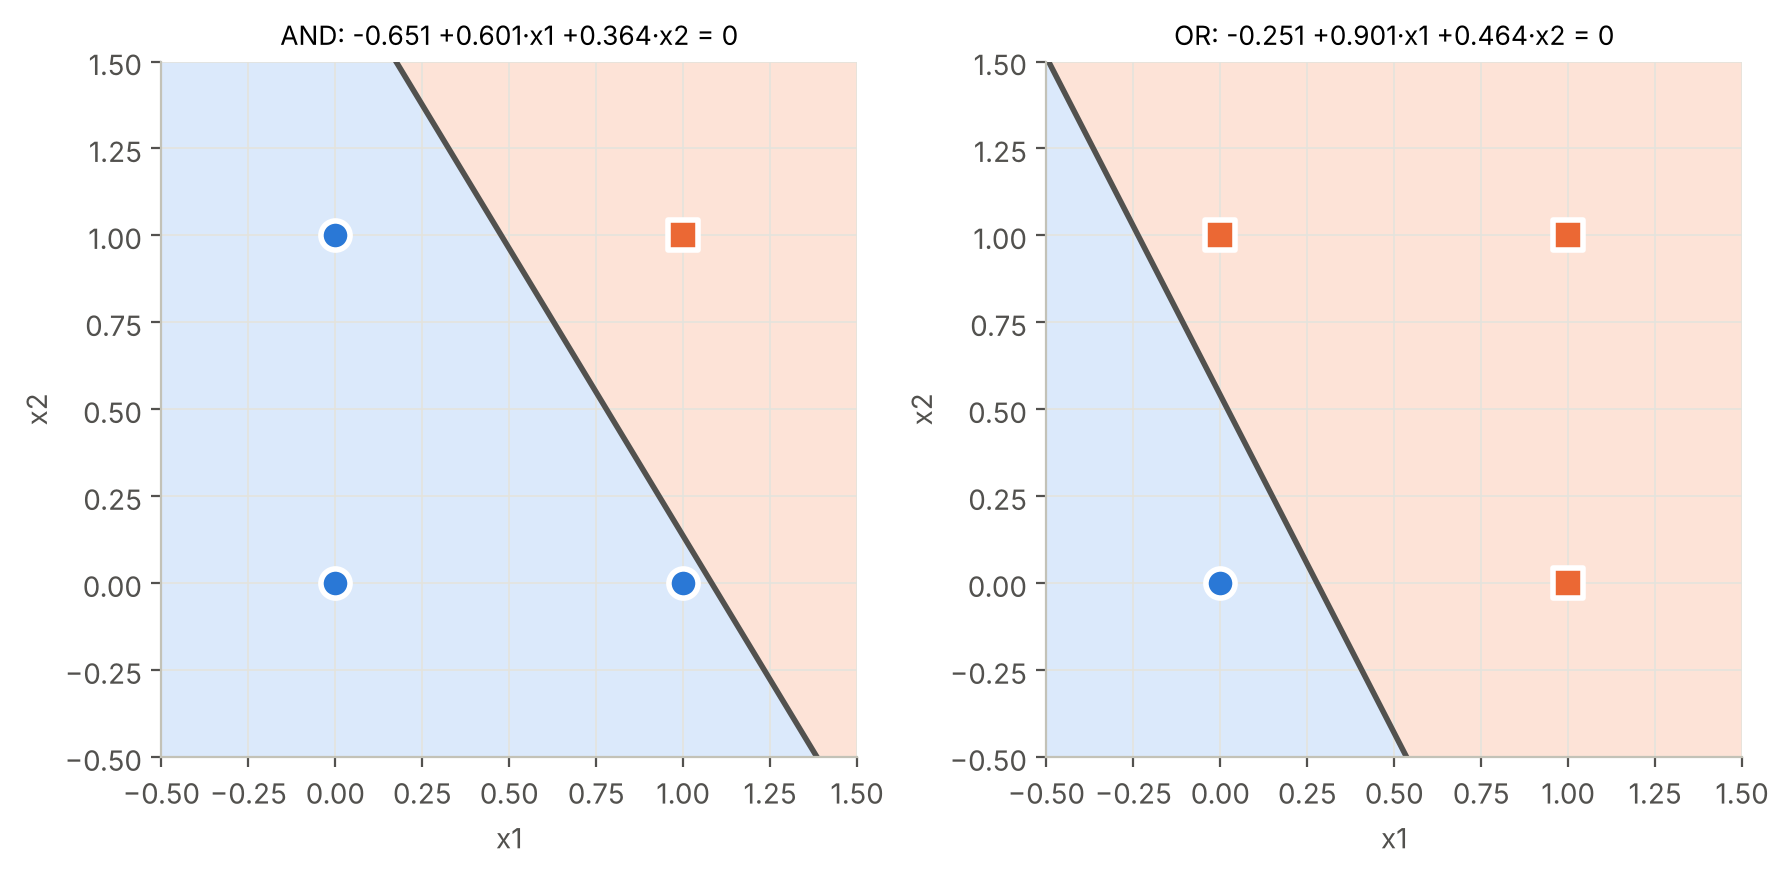

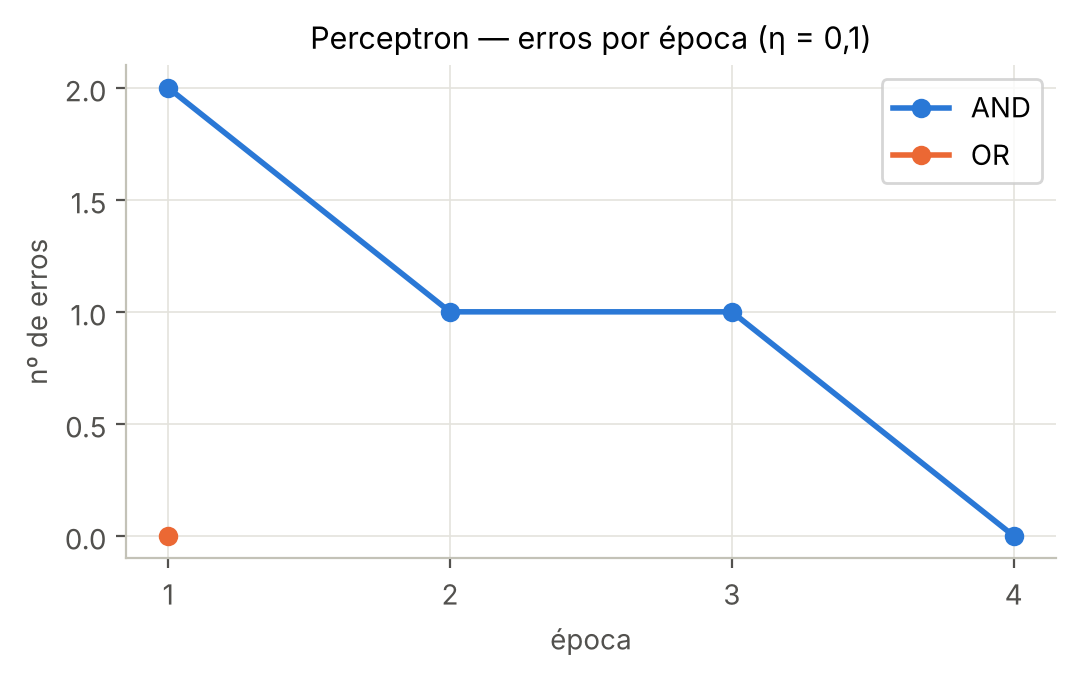

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(9, 4.4))
for ax, (f, m) in zip(axs, modelos.items()):
    plotar_regioes(ax, m)
    plotar_pontos(ax, ALVOS[f])
    plotar_reta(ax, m.w)
    ax.set_title(f"{f}: {equacao(m.w)}", fontsize=9.5)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.2))
for (f, m), cor in zip(modelos.items(), [AZUL, LARANJA]):
    ax.plot(range(1, m.epocas_ + 1), m.erros_por_epoca_, "o-", color=cor, lw=2, label=f)
ax.set(xlabel="época", ylabel="nº de erros", title="Perceptron — erros por época (η = 0,1)")
ax.set_xticks(range(1, max(m.epocas_ for m in modelos.values()) + 1))
ax.legend(); plt.show()

### Pergunta (ii) — teste com η = 0,5 (mesmos pesos iniciais)

In [10]:
linhas = []
for f in ["AND", "OR"]:
    for eta in [0.1, 0.5]:
        linhas.append(resumo(f, Perceptron(eta=eta, w_inicial=W_INICIAL).fit(X_LOGICO, ALVOS[f]), ALVOS[f]))
tab_eta = pd.DataFrame(linhas)
tab_eta

,função,η,w0,w1,w2,atualizações,épocas,convergiu,acurácia
0,AND,0.1,-0.6509,0.6014,0.364,4,4,True,1.0
1,AND,0.5,-1.2509,0.9014,0.464,6,4,True,1.0
2,OR,0.1,-0.2509,0.9014,0.464,0,1,True,1.0
3,OR,0.5,-0.2509,0.9014,0.464,0,1,True,1.0


**Respostas**

**(i)** No AND só (1,1) é classe 1, então a reta precisa isolá-lo; no OR só (0,0) é classe 0, então basta isolar a origem. Como há infinitas retas válidas, o Perceptron para na primeira que encontra, e ela depende dos pesos iniciais. Com a semente 42, a reta inicial já separava o OR (0 atualizações); no AND foram necessárias 4.

**(ii)** Muda: o AND passou de 4 para 6 atualizações com η = 0,5 (o OR seguiu com 0, pois nunca errou). Cada correção soma η·x aos pesos; com passos maiores a reta anda mais a cada erro, pode passar do ponto e exigir novas correções.

## Exercício 3 — Limitação do Perceptron: XOR

In [11]:
ETAS = [0.01, 0.1, 0.5]
xor = {eta: Perceptron(eta=eta, max_epocas=100, w_inicial=W_INICIAL).fit(X_LOGICO, ALVOS["XOR"])
       for eta in ETAS}

tab_xor = pd.DataFrame([{
    "η": eta, "épocas": m.epocas_, "convergiu": m.convergiu_,
    "atualizações": m.n_atualizacoes_,
    "acurácia final": m.acuracia_por_epoca_[-1],
    "acurácia máxima (todas as épocas)": max(m.acuracia_por_epoca_),
    "w0": m.w[0], "w1": m.w[1], "w2": m.w[2]} for eta, m in xor.items()])
tab_xor

,η,épocas,convergiu,atualizações,acurácia final,acurácia máxima (todas as épocas),w0,w1,w2
0,0.01,100,False,204,0.25,0.75,-0.2109,0.2014,0.204
1,0.10,100,False,367,0.50,0.75,0.0491,-0.0986,-0.036
2,0.50,100,False,391,0.50,0.50,0.2491,-0.5986,-0.036


In [12]:
# 3(c) A acurácia nunca chega a 100% em nenhuma época, para nenhum η
for eta, m in xor.items():
    acc = np.array(m.acuracia_por_epoca_)
    assert acc.max() < 1.0
    print(f"η = {eta:<4}: acurácia máxima em 100 épocas = {acc.max():.0%}; épocas com 100%: {(acc == 1).sum()}")

η = 0.01: acurácia máxima em 100 épocas = 75%; épocas com 100%: 0
η = 0.1 : acurácia máxima em 100 épocas = 75%; épocas com 100%: 0
η = 0.5 : acurácia máxima em 100 épocas = 50%; épocas com 100%: 0


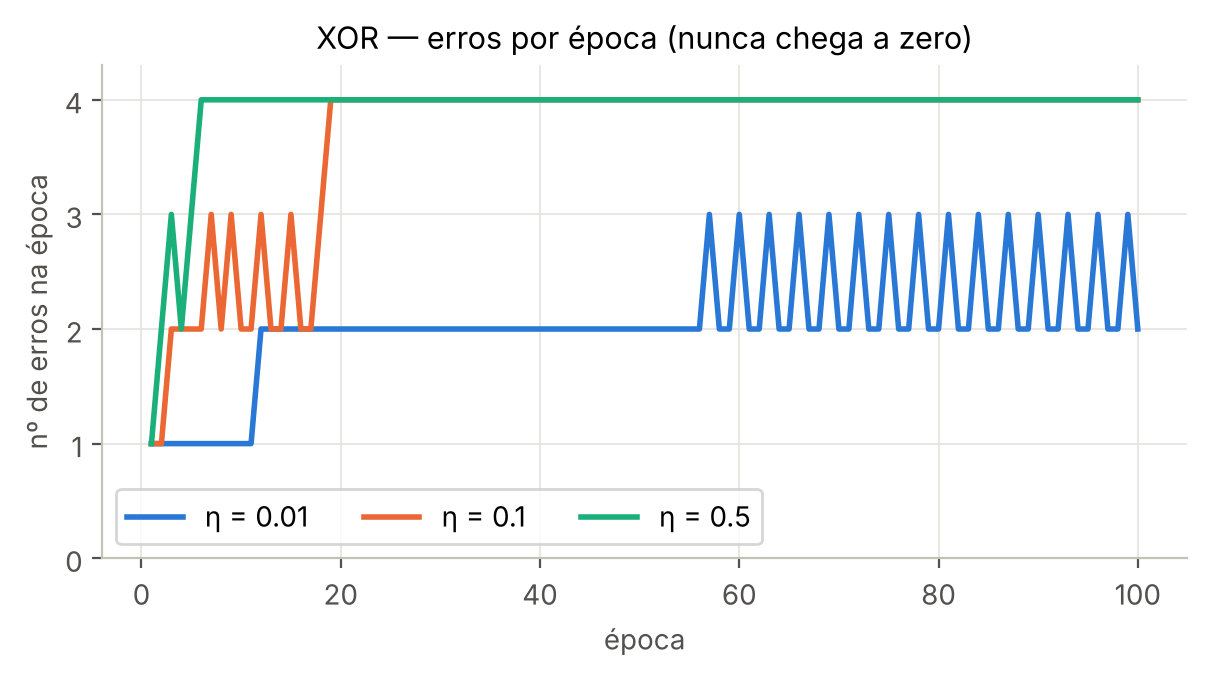

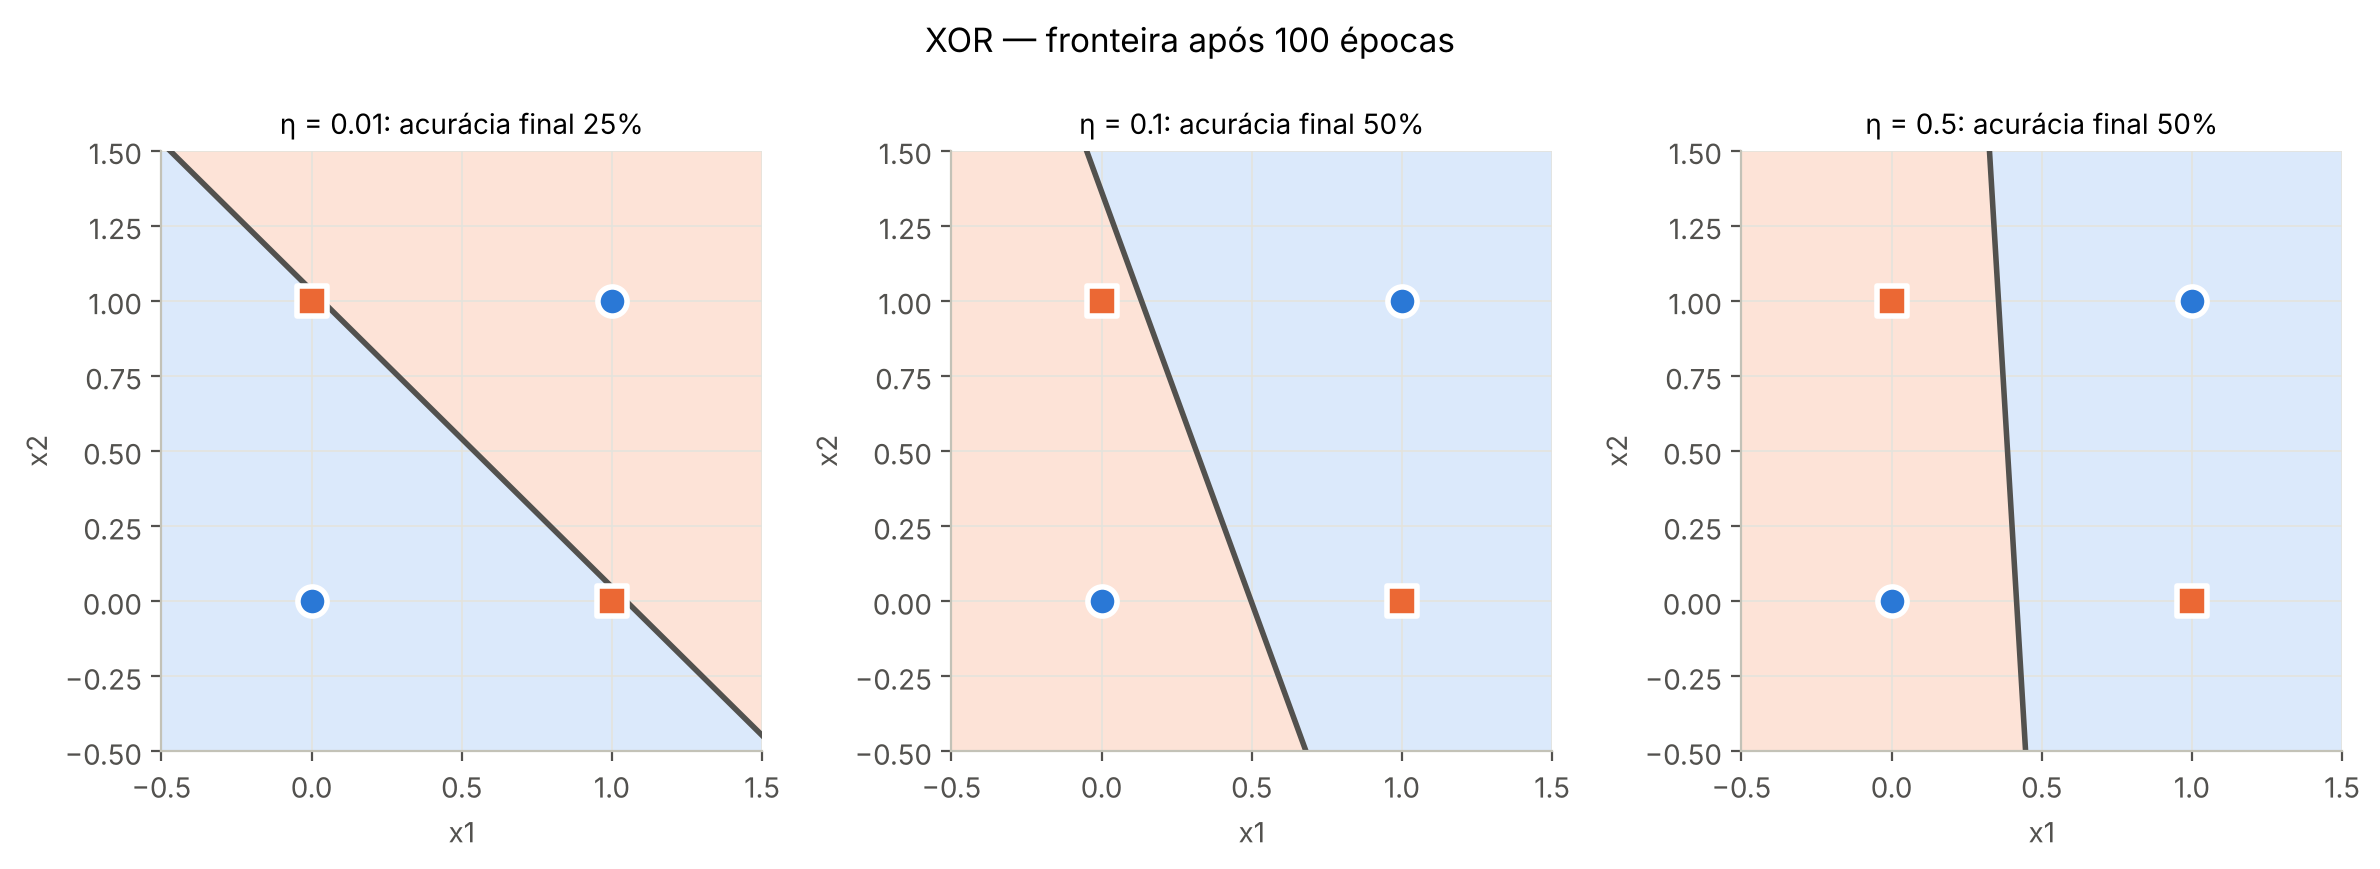

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for (eta, m), cor in zip(xor.items(), [AZUL, LARANJA, VERDE]):
    ax.plot(range(1, m.epocas_ + 1), m.erros_por_epoca_, color=cor, lw=2, label=f"η = {eta}")
ax.set(xlabel="época", ylabel="nº de erros na época", ylim=(0, 4.3),
       title="XOR — erros por época (nunca chega a zero)")
ax.legend(ncol=3); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, (eta, m) in zip(axs, xor.items()):
    plotar_regioes(ax, m)
    plotar_pontos(ax, ALVOS["XOR"])
    plotar_reta(ax, m.w)
    ax.set_title(f"η = {eta}: acurácia final {m.acuracia_por_epoca_[-1]:.0%}", fontsize=10)
plt.suptitle("XOR — fronteira após 100 épocas", y=1.0)
plt.tight_layout(); plt.show()

**Respostas**

**(i)** Os pontos da classe 1, (0,1) e (1,0), ficam numa diagonal do quadrado e os da classe 0, (0,0) e (1,1), na outra; as diagonais se cruzam em (0,5; 0,5). Cada lado de uma reta é convexo, então esse ponto teria de estar ao mesmo tempo do lado da classe 1 e do lado da classe 0, o que é impossível.

**(ii)** Não. η só muda o tamanho do passo; o Perceptron só converge com dados linearmente separáveis, então os pesos ficam oscilando.

**(iii)** Uma camada oculta com ativação não linear (rede 2–2–1), que combina duas retas.

---
# Parte 2 — Backpropagation

**Decisões:** sigmoide e bias em todos os neurônios; pesos iniciais uniformes em $[-0{,}5;\ 0{,}5]$; $\delta_{oculto}$ calculado antes de atualizar os pesos de saída; no XOR, ordem das instâncias embaralhada a cada época; no mini-batch, $\Delta w$ é a média no lote; MSE medido ao fim de cada época.

In [14]:
def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-z))


class RedeMLP:
    # Rede com 1 camada oculta, sigmoide em todos os neurônios, bias e erro quadrático.

    def __init__(self, n_entradas, n_ocultos, eta=0.5, escala=0.5, seed=SEED):
        np.random.seed(seed)
        self.eta = eta
        u = lambda *forma: np.random.uniform(-escala, escala, forma)   # pesos pequenos
        self.W1, self.b1 = u(n_ocultos, n_entradas), u(n_ocultos)      # entrada -> oculta
        self.W2, self.b2 = u(1, n_ocultos), u(1)                       # oculta  -> saída

    # ---------- forward ----------
    def forward(self, X):
        z1 = X @ self.W1.T + self.b1     # entrada líquida dos neurônios ocultos
        h = sigmoide(z1)                 # saída da camada oculta
        z2 = h @ self.W2.T + self.b2     # entrada líquida do neurônio de saída
        y = sigmoide(z2)                 # saída da rede
        return z1, h, z2, y

    # ---------- backward ----------
    def deltas(self, d, h, y):
        delta_s = (d - y) * y * (1 - y)                # δ_saída = (d − y)·y(1 − y)
        delta_h = h * (1 - h) * (delta_s @ self.W2)    # δ_oculto = h(1 − h)·Σ w·δ_saída
        return delta_s, delta_h

    def gradientes(self, X, d):
        # Gradiente analítico de E = ½·Σ(d − y)² (soma nas linhas de X): ∂E/∂w = −δ·x
        _, h, _, y = self.forward(X)
        ds, dh = self.deltas(d, h, y)
        return {"W1": -(dh.T @ X), "b1": -dh.sum(0), "W2": -(ds.T @ h), "b2": -ds.sum(0)}

    def passo(self, X, d):
        # Uma atualização Δw = η·δ·x (média no lote; com lote de 1 é exatamente a regra do enunciado)
        g, n = self.gradientes(X, d), len(X)
        self.W1 -= self.eta * g["W1"] / n
        self.b1 -= self.eta * g["b1"] / n
        self.W2 -= self.eta * g["W2"] / n
        self.b2 -= self.eta * g["b2"] / n

    # ---------- treino e predição ----------
    def fit(self, X, d, epocas, tam_lote=1, X_teste=None, d_teste=None, seed=SEED):
        d = d.reshape(-1, 1).astype(float)
        np.random.seed(seed)
        self.mse_treino_, self.mse_teste_ = [], []
        for _ in range(epocas):
            ordem = np.random.permutation(len(X))           # embaralha a cada época
            for i in range(0, len(X), tam_lote):
                idx = ordem[i:i + tam_lote]
                self.passo(X[idx], d[idx])
            self.mse_treino_.append(self.mse(X, d))         # MSE ao fim da época
            if X_teste is not None:
                self.mse_teste_.append(self.mse(X_teste, d_teste))
        return self

    def mse(self, X, d):
        return float(np.mean((d.reshape(-1, 1) - self.forward(X)[3]) ** 2))

    def predict_proba(self, X):
        return self.forward(X)[3].ravel()

    def predict(self, X, limiar=0.5):
        return (self.predict_proba(X) >= limiar).astype(int)

## Exercício 1 — Rede 2–2–1 no XOR

### 1(a) Forward com os pesos iniciais

In [15]:
D_XOR = ALVOS["XOR"].astype(float)
rede_xor = RedeMLP(2, 2, eta=0.5, seed=SEED)
pesos_ini_xor = {k: getattr(rede_xor, k).copy() for k in ["W1", "b1", "W2", "b2"]}
for k, v in pesos_ini_xor.items():
    print(f"{k} =", np.round(v, 4).tolist())

z1, h, z2, y = rede_xor.forward(X_LOGICO)
pd.DataFrame({"x1": X_LOGICO[:, 0], "x2": X_LOGICO[:, 1],
              "z1 (h1)": z1[:, 0], "z1 (h2)": z1[:, 1], "h1": h[:, 0], "h2": h[:, 1],
              "z2": z2[:, 0], "y": y[:, 0], "d": D_XOR})

W1 = [[-0.1255, 0.4507], [0.232, 0.0987]]
b1 = [-0.344, -0.344]
W2 = [[-0.4419, 0.3662]]
b2 = [0.1011]


,x1,x2,z1 (h1),z1 (h2),h1,h2,z2,y,d
0,0.0,0.0,-0.3440,-0.3440,0.4148,0.4148,0.0697,0.5174,0.0
1,0.0,1.0,0.1067,-0.2453,0.5267,0.4390,0.0291,0.5073,1.0
2,1.0,0.0,-0.4694,-0.1120,0.3847,0.4720,0.1039,0.5260,1.0
3,1.0,1.0,-0.0187,-0.0134,0.4953,0.4967,0.0641,0.5160,0.0


### 1(b) Backward: deltas e atualização dos pesos (entrada (0, 1), d = 1)

In [16]:
import copy
demo = copy.deepcopy(rede_xor)
x, d = X_LOGICO[[1]], D_XOR[[1]].reshape(-1, 1)
_, h_, _, y_ = demo.forward(x)
ds, dh = demo.deltas(d, h_, y_)
print(f"y = {y_[0,0]:.4f}  ->  δ_saída = (d − y)·y(1 − y) = {ds[0,0]:.5f}")
print("δ_oculto = h(1 − h)·w·δ_saída =", np.round(dh[0], 5))
print("ΔW2 = η·δ_saída·h =", np.round(demo.eta * ds[0, 0] * h_[0], 5), "| Δb2 =", np.round(demo.eta * ds[0, 0], 5))
print("ΔW1 = η·δ_oculto·x =\n", np.round(demo.eta * dh.T @ x, 5), "| Δb1 =", np.round(demo.eta * dh[0], 5))

y = 0.5073  ->  δ_saída = (d − y)·y(1 − y) = 0.12315
δ_oculto = h(1 − h)·w·δ_saída = [-0.01357  0.01111]
ΔW2 = η·δ_saída·h = [0.03243 0.02703] | Δb2 = 0.06158
ΔW1 = η·δ_oculto·x =
 [[ 0.      -0.00678]
 [ 0.       0.00555]] | Δb1 = [-0.00678  0.00555]


### 1(c) Treino: η = 0,5; 10.000 épocas; SGD por instância

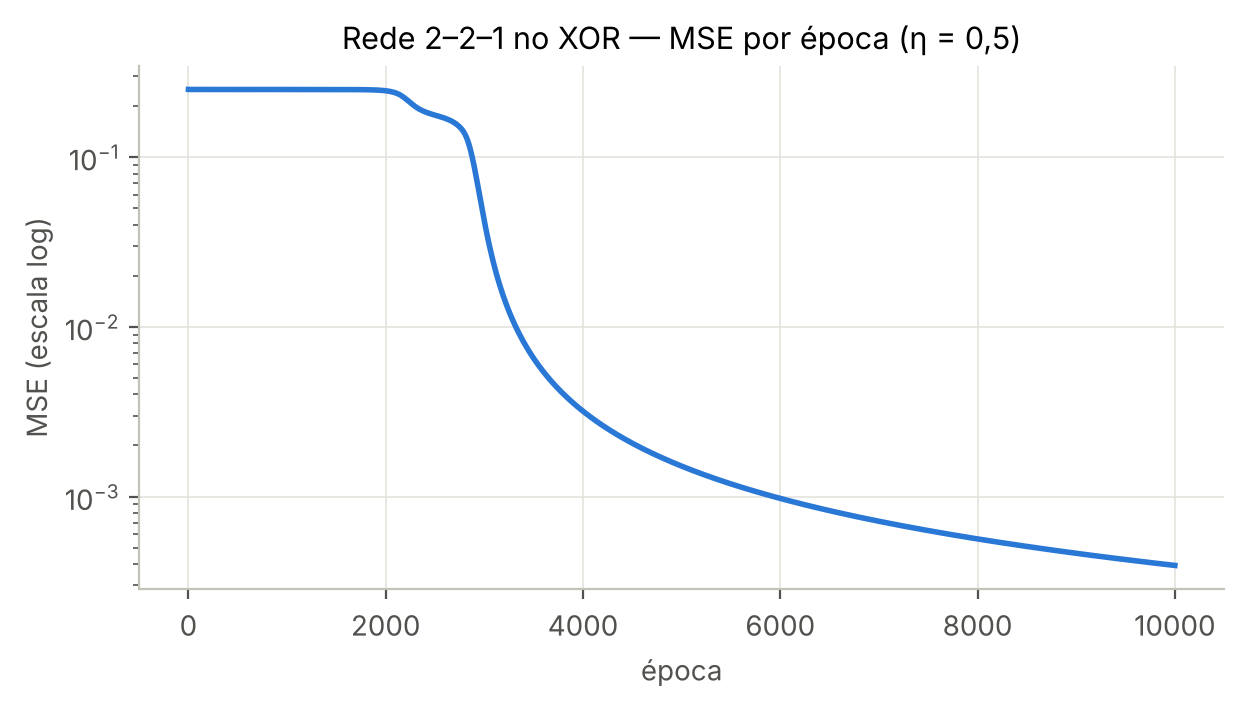

MSE: época 1 = 0.2503 | época 10.000 = 0.00039


In [17]:
rede_xor.fit(X_LOGICO, D_XOR, epocas=10_000, tam_lote=1, seed=SEED)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(range(1, 10_001), rede_xor.mse_treino_, color=AZUL, lw=2)
ax.set(yscale="log", xlabel="época", ylabel="MSE (escala log)",
       title="Rede 2–2–1 no XOR — MSE por época (η = 0,5)")
plt.show()
print(f"MSE: época 1 = {rede_xor.mse_treino_[0]:.4f} | época 10.000 = {rede_xor.mse_treino_[-1]:.5f}")

### 1(d) Saídas finais e acurácia (limiar 0,5)

In [18]:
saidas_xor = pd.DataFrame({"x1": X_LOGICO[:, 0].astype(int), "x2": X_LOGICO[:, 1].astype(int),
                           "d": ALVOS["XOR"], "y (saída)": rede_xor.predict_proba(X_LOGICO),
                           "classe prevista": rede_xor.predict(X_LOGICO)})
acc_xor = np.mean(saidas_xor["classe prevista"] == saidas_xor["d"])
print(f"Acurácia: {acc_xor:.0%}")
saidas_xor

Acurácia: 100%


,x1,x2,d,y (saída),classe prevista
0,0,0,0,0.0177,0
1,0,1,1,0.9812,1
2,1,0,1,0.9811,1
3,1,1,0,0.0234,0


### 1(e) Verificação do gradiente

Peso verificado: $W_1[0,0]$ (entrada $x_1$ → neurônio oculto 1), nos pesos iniciais, com $E = \tfrac12\sum(d-y)^2$ nas 4 linhas.

In [19]:
EPS = 1e-5
rede_g = RedeMLP(2, 2, seed=SEED)                       # mesmos pesos iniciais
E = lambda r: 0.5 * np.sum((D_XOR.reshape(-1, 1) - r.forward(X_LOGICO)[3]) ** 2)
g_analitico = rede_g.gradientes(X_LOGICO, D_XOR.reshape(-1, 1))["W1"][0, 0]   # backprop: −δ·x

original = rede_g.W1[0, 0]
rede_g.W1[0, 0] = original + EPS; E_mais = E(rede_g)
rede_g.W1[0, 0] = original - EPS; E_menos = E(rede_g)
rede_g.W1[0, 0] = original
g_numerico = (E_mais - E_menos) / (2 * EPS)
dif_grad = abs(g_analitico - g_numerico)
print(f"Analítico: {g_analitico:.10f} | Diferença finita: {g_numerico:.10f} | "
      f"Diferença: {dif_grad:.2e} (< 1e-6? {dif_grad < 1e-6})")

Analítico: -0.0018725938 | Diferença finita: -0.0018725938 | Diferença: 3.10e-12 (< 1e-6? True)


### 1(f) Cinco sementes (0 a 4)

Convergiu = acertar as 4 linhas e terminar com MSE < 0,05.

In [20]:
linhas = []
for s in [0, 1, 2, 3, 4]:
    r = RedeMLP(2, 2, eta=0.5, seed=s).fit(X_LOGICO, D_XOR, epocas=10_000, seed=s)
    acc = np.mean(r.predict(X_LOGICO) == ALVOS["XOR"])
    linhas.append({"semente": s, "acurácia": acc, "MSE final": r.mse_treino_[-1],
                   "convergiu": bool(acc == 1 and r.mse_treino_[-1] < 0.05)})
tab_sementes = pd.DataFrame(linhas)
print(f"Convergiram: {tab_sementes['convergiu'].sum()} de 5")
tab_sementes

Convergiram: 5 de 5


,semente,acurácia,MSE final,convergiu
0,0,1.0,0.0004,True
1,1,1.0,0.0003,True
2,2,1.0,0.0003,True
3,3,1.0,0.0003,True
4,4,1.0,0.0004,True


**Respostas**

**(i)** O Perceptron tem uma só fronteira linear. Na rede 2–2–1, cada neurônio oculto traça uma reta e a saída combina as duas regiões; o Backpropagation consegue ajustar os pesos ocultos porque os δ levam o erro da saída até eles.

**(ii)** A superfície de erro não é convexa. Com pesos pequenos, as saídas começam perto de 0,5 e o gradiente é pequeno (platô: aqui o MSE ficou em ≈ 0,25 até perto da época 2.000). Se um neurônio oculto satura, $h(1-h) \approx 0$, o gradiente quase some e a rede pode parar num mínimo local. Isso depende dos pesos iniciais e da ordem das instâncias, ou seja, da semente.

## Exercício 2 — Backpropagation na base Titanic

### 2(a) Carga e pré-processamento

Base `train.csv` do Titanic (891 passageiros), a mesma das listas anteriores: o notebook lê `titanic.csv` se o arquivo estiver no Colab; senão, baixa uma cópia pública.

**Decisões** (tudo que aprende parâmetros é ajustado só no treino):
- `sex`: 1 = feminino; `pclass` mantida ordinal (1, 2, 3); `fare` em $\log(1+\text{fare})$, por ser muito assimétrica.
- `age` (177 faltantes): imputação KNN (k = 5).
- Padronização z-score.
- Balanceamento SMOTE (k = 5) só no treino; nos atributos discretos a amostra sintética copia o valor do ponto mais próximo.

In [21]:
URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
CAMINHO_LOCAL = "titanic.csv"
try:
    bruto = pd.read_csv(CAMINHO_LOCAL)
except FileNotFoundError:
    bruto = pd.read_csv(URL_TITANIC)

bruto.columns = bruto.columns.str.lower()
ATRIBUTOS = ["pclass", "sex", "age", "sibsp", "parch", "fare"]
DISCRETOS = [0, 1, 3, 4]                       # índices de pclass, sex, sibsp, parch
df = bruto[ATRIBUTOS + ["survived"]].copy()
df["sex"] = (df["sex"].str.lower() == "female").astype(int)   # 1 = feminino
df["fare"] = np.log1p(df["fare"])

df.isna().sum().to_frame("faltantes").T

,pclass,sex,age,sibsp,parch,fare,survived
faltantes,0,0,177,0,0,0,0


In [22]:
def divisao_estratificada(y, prop_teste=0.2, seed=SEED):
    # Separa prop_teste de CADA classe para o teste (mantém a proporção de sobreviventes).
    np.random.seed(seed)
    treino, teste = [], []
    for classe in np.unique(y):
        idx = np.random.permutation(np.where(y == classe)[0])
        n_teste = int(round(prop_teste * len(idx)))
        teste += idx[:n_teste].tolist(); treino += idx[n_teste:].tolist()
    return np.array(sorted(treino)), np.array(sorted(teste))


class ImputadorKNN:
    # Imputa uma coluna pela média dos k vizinhos mais próximos do TREINO.
    # A distância usa as demais colunas padronizadas (com média/desvio do treino).
    def __init__(self, coluna, k=5):
        self.coluna, self.k = coluna, k

    def fit(self, X):
        ok = ~np.isnan(X[:, self.coluna])
        self.outras = [j for j in range(X.shape[1]) if j != self.coluna]
        ref = X[ok][:, self.outras]
        self.media, self.desvio = ref.mean(0), ref.std(0)
        self.ref = (ref - self.media) / self.desvio
        self.valores_ref = X[ok, self.coluna]
        return self

    def transform(self, X):
        X = X.copy()
        faltam = np.where(np.isnan(X[:, self.coluna]))[0]
        Z = (X[faltam][:, self.outras] - self.media) / self.desvio
        dist = ((Z[:, None, :] - self.ref[None, :, :]) ** 2).sum(-1)
        vizinhos = np.argsort(dist, axis=1)[:, :self.k]
        X[faltam, self.coluna] = self.valores_ref[vizinhos].mean(1)
        return X


class Padronizador:
    def fit(self, X):
        self.media, self.desvio = X.mean(0), X.std(0)
        return self
    def transform(self, X):
        return (X - self.media) / self.desvio


def smote(X, y, k=5, discretos=(), seed=SEED):
    # SMOTE: cria amostras sintéticas da classe minoritária até igualar as classes.
    np.random.seed(seed)
    classes, cont = np.unique(y, return_counts=True)
    minor = classes[np.argmin(cont)]
    n_novas = cont.max() - cont.min()
    Xm = X[y == minor]
    dist = ((Xm[:, None, :] - Xm[None, :, :]) ** 2).sum(-1)
    np.fill_diagonal(dist, np.inf)
    vizinhos = np.argsort(dist, axis=1)[:, :k]
    base = np.random.randint(0, len(Xm), n_novas)
    viz = vizinhos[base, np.random.randint(0, k, n_novas)]
    lam = np.random.rand(n_novas, 1)
    novas = Xm[base] + lam * (Xm[viz] - Xm[base])          # ponto no segmento base–vizinho
    for j in discretos:                                    # discretos: valor do ponto mais próximo
        novas[:, j] = np.where(lam[:, 0] < 0.5, Xm[base, j], Xm[viz, j])
    return np.vstack([X, novas]), np.concatenate([y, np.full(n_novas, minor)])

In [23]:
X_total = df[ATRIBUTOS].to_numpy(float)
y_total = df["survived"].to_numpy(int)

# 2(b) Divisão estratificada 80/20
i_tr, i_te = divisao_estratificada(y_total, 0.2, SEED)
X_tr_bruto, X_te_bruto = X_total[i_tr], X_total[i_te]
y_tr_orig, y_te = y_total[i_tr], y_total[i_te]

# Imputação KNN da idade (ajustada só no treino)
imp = ImputadorKNN(coluna=2, k=5).fit(X_tr_bruto)
X_tr_imp, X_te_imp = imp.transform(X_tr_bruto), imp.transform(X_te_bruto)

# Padronização (média/desvio do treino)
pad = Padronizador().fit(X_tr_imp)
X_tr_pad, X_te = pad.transform(X_tr_imp), pad.transform(X_te_imp)

# SMOTE só no treino e embaralhamento
X_tr, y_tr = smote(X_tr_pad, y_tr_orig, k=5, discretos=DISCRETOS, seed=SEED)
np.random.seed(SEED)
p = np.random.permutation(len(y_tr))
X_tr, y_tr = X_tr[p], y_tr[p]

pd.DataFrame({
    "conjunto": ["treino (original)", "treino (após SMOTE)", "teste"],
    "linhas": [len(y_tr_orig), len(y_tr), len(y_te)],
    "sobreviventes (1)": [y_tr_orig.sum(), y_tr.sum(), y_te.sum()],
    "% classe 1": [y_tr_orig.mean(), y_tr.mean(), y_te.mean()]}).round(3)

,conjunto,linhas,sobreviventes (1),% classe 1
0,treino (original),713,274,0.384
1,treino (após SMOTE),878,439,0.500
2,teste,178,68,0.382


### 2(c) Modelo: 6–8–1, sigmoide, mini-batch 32, η = 0,1, 200 épocas

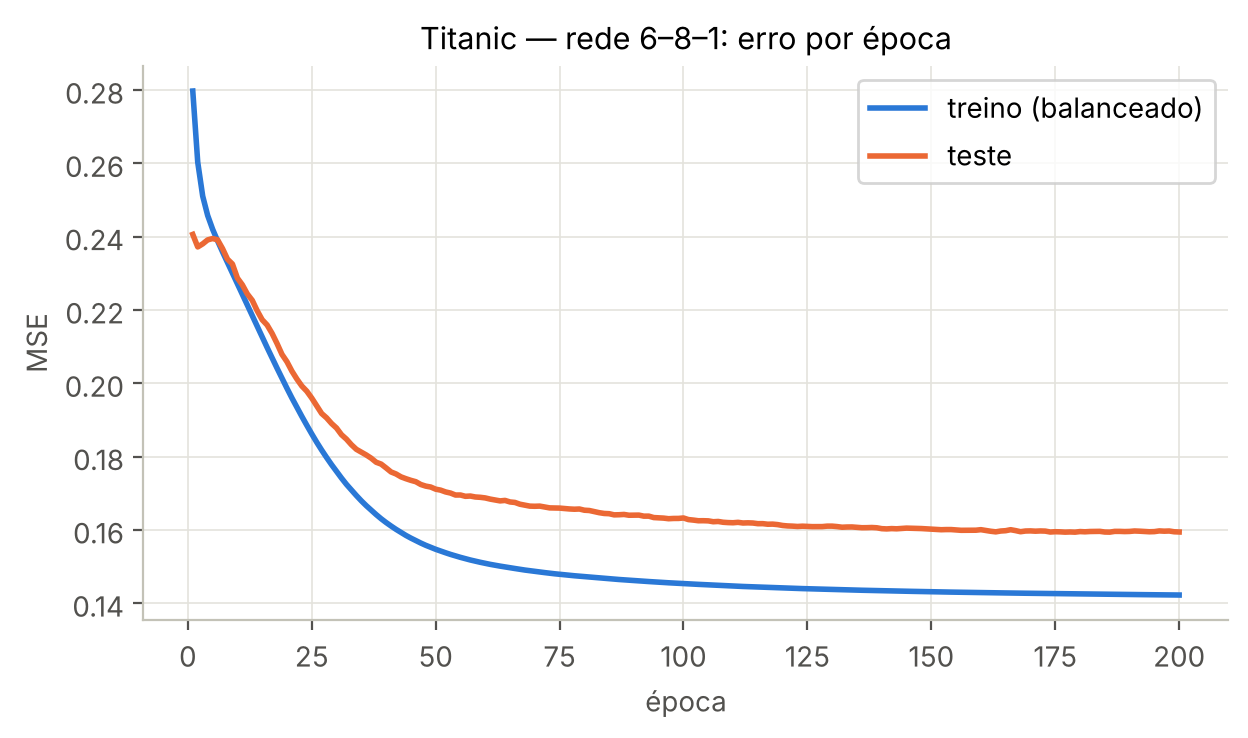

In [24]:
rede_tit = RedeMLP(6, 8, eta=0.1, seed=SEED)
rede_tit.fit(X_tr, y_tr, epocas=200, tam_lote=32, X_teste=X_te, d_teste=y_te, seed=SEED)

# 2(d) Curvas de erro
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(range(1, 201), rede_tit.mse_treino_, color=AZUL, lw=2, label="treino (balanceado)")
ax.plot(range(1, 201), rede_tit.mse_teste_, color=LARANJA, lw=2, label="teste")
ax.set(xlabel="época", ylabel="MSE", title="Titanic — rede 6–8–1: erro por época")
ax.legend(); plt.show()

### 2(e) Métricas no teste e 2(f) comparação com as referências

In [25]:
def metricas(y, y_pred):
    vp = int(np.sum((y == 1) & (y_pred == 1))); vn = int(np.sum((y == 0) & (y_pred == 0)))
    fp = int(np.sum((y == 0) & (y_pred == 1))); fn = int(np.sum((y == 1) & (y_pred == 0)))
    prec = vp / (vp + fp) if vp + fp > 0 else np.nan     # indefinida se nunca prevê 1
    rev = vp / (vp + fn) if vp + fn > 0 else np.nan
    return {"acurácia": (vp + vn) / len(y), "precisão (1)": prec, "revocação (1)": rev,
            "VN": vn, "FP": fp, "FN": fn, "VP": vp}

def matriz_confusao(y, y_pred):
    m = metricas(y, y_pred)
    return pd.DataFrame([[m["VN"], m["FP"]], [m["FN"], m["VP"]]],
                        index=["real 0 (morreu)", "real 1 (sobreviveu)"],
                        columns=["previsto 0", "previsto 1"])

pred_rede = rede_tit.predict(X_te)
print("Matriz de confusão da rede 6–8–1 (teste):")
display(matriz_confusao(y_te, pred_rede))

# Referência (i): classe majoritária do treino ORIGINAL (antes do SMOTE)
majoritaria = np.bincount(y_tr_orig).argmax()
pred_maj = np.full(len(y_te), majoritaria)

# Referência (ii): Perceptron do Exercício 1 nos mesmos dados (η = 0,1; 100 épocas)
perc_tit = Perceptron(eta=0.1, max_epocas=100, seed=SEED).fit(X_tr, y_tr)
pred_perc = perc_tit.predict(X_te)
print(f"Perceptron no Titanic: convergiu = {perc_tit.convergiu_}, "
      f"erros na última época = {perc_tit.erros_por_epoca_[-1]} de {len(y_tr)}")

tab_comp = pd.DataFrame({
    "Rede 6–8–1 (backprop)": metricas(y_te, pred_rede),
    f"Classe majoritária ({majoritaria})": metricas(y_te, pred_maj),
    "Perceptron": metricas(y_te, pred_perc)}).T
tab_comp

Matriz de confusão da rede 6–8–1 (teste):


,previsto 0,previsto 1
real 0 (morreu),88,22
real 1 (sobreviveu),17,51


Perceptron no Titanic: convergiu = False, erros na última época = 260 de 878


,acurácia,precisão (1),revocação (1),VN,FP,FN,VP
Rede 6–8–1 (backprop),0.7809,0.6986,0.7500,88.0,22.0,17.0,51.0
Classe majoritária (0),0.6180,NaN,0.0000,110.0,0.0,68.0,0.0
Perceptron,0.7191,0.6047,0.7647,76.0,34.0,16.0,52.0


### 2(g) Neurônios ocultos: 2, 8 e 32

In [26]:
tab_h = pd.DataFrame([{
    "neurônios ocultos": H,
    "acurácia teste": np.mean(RedeMLP(6, H, eta=0.1, seed=SEED)
                              .fit(X_tr, y_tr, epocas=200, tam_lote=32, seed=SEED)
                              .predict(X_te) == y_te)} for H in [2, 8, 32]])
tab_h

,neurônios ocultos,acurácia teste
0,2,0.7640
1,8,0.7809
2,32,0.7697


**Respostas**

**(i)** Sim: 78,1% de acurácia contra 71,9% do Perceptron e 61,8% da classe majoritária, que nunca prevê sobrevivente. O Perceptron não converge, pois os dados não são linearmente separáveis, e fica com os pesos da última atualização; a rede tem fronteira não linear e minimiza um erro contínuo.

**(ii)** Não há sinal relevante: as curvas de treino e teste caem juntas e se estabilizam, e o erro de teste não volta a subir.

**(iii)** Como Δw = η·δ·x, atributos com valores grandes (idade até 80) recebem passos muito maiores que os binários, e um único η não serve para todos. Entradas grandes também saturam a sigmoide ($h(1-h) \approx 0$), o que anula os δ. Com z-score, todos ficam em escala parecida, perto de 0.